## Descripción del proyecto

La cadena de supermercados Good Seed desea explorar el uso de visión artificial para ayudar a cumplir las leyes que restringen la venta de alcohol a menores de edad.

Las tiendas cuentan con cámaras en las áreas de pago que se activan cuando un cliente compra alcohol. A partir de las imágenes capturadas, se busca desarrollar un modelo de aprendizaje profundo capaz de estimar la edad de una persona.

## Objetivo

Construir y evaluar un modelo de visión artificial que prediga la edad de una persona a partir de una fotografía facial.

## Pasos del proyecto

1. Cargar y explorar el conjunto de datos.
2. Analizar la distribución de edades.
3. Visualizar una muestra de imágenes.
4. Preparar los datos para el entrenamiento.
5. Entrenar un modelo de red neuronal convolucional.
6. Evaluar el rendimiento del modelo.
7. Formular conclusiones y recomendaciones para Good Seed.

## Datos utilizados

- `/datasets/faces/labels.csv`
- `/datasets/faces/final_files/`

## Métrica de evaluación

El desempeño del modelo se evaluará mediante el Error Absoluto Medio (MAE), que indica cuántos años se equivoca el modelo, en promedio, al estimar la edad de una persona.

La carpeta que contiene las fotos de personas de variadas edades se extrajó desde la nube google drive por motivos de tamaño del archivo total

In [3]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
import zipfile

zip_path = '/content/drive/MyDrive/final_files.zip'

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall('/content/faces')

print("Descompresión completada")

Descompresión completada


In [5]:
import os

os.listdir('/content/faces')

['000831.jpg',
 '004273.jpg',
 '005588.jpg',
 '004284.jpg',
 '005066.jpg',
 '005681.jpg',
 '005258.jpg',
 '005892.jpg',
 '000257.jpg',
 '003296.jpg',
 '000322.jpg',
 '005157.jpg',
 '005443.jpg',
 '005370.jpg',
 '003195.jpg',
 '005478.jpg',
 '003257.jpg',
 '000913.jpg',
 '003521.jpg',
 '004935.jpg',
 '005059.jpg',
 '006743.jpg',
 '002590.jpg',
 '002482.jpg',
 '000595.jpg',
 '003712.jpg',
 '006337.jpg',
 '003916.jpg',
 '007151.jpg',
 '006469.jpg',
 '005639.jpg',
 '005034.jpg',
 '002565.jpg',
 '002672.jpg',
 '000545.jpg',
 '000655.jpg',
 '003873.jpg',
 '001892.jpg',
 '004768.jpg',
 '000635.jpg',
 '006712.jpg',
 '001046.jpg',
 '004457.jpg',
 '004714.jpg',
 '000708.jpg',
 '000031.jpg',
 '002257.jpg',
 '005676.jpg',
 '007588.jpg',
 '002081.jpg',
 '002790.jpg',
 '001396.jpg',
 '001317.jpg',
 '001899.jpg',
 '006902.jpg',
 '002097.jpg',
 '007010.jpg',
 '000739.jpg',
 '002516.jpg',
 '006324.jpg',
 '004630.jpg',
 '004473.jpg',
 '000511.jpg',
 '003094.jpg',
 '000884.jpg',
 '006976.jpg',
 '007340.j

In [6]:
import pandas as pd

labels = pd.read_csv("/content/labels.csv")

In [7]:
labels.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7591 entries, 0 to 7590
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   file_name  7591 non-null   object
 1   real_age   7591 non-null   int64 
dtypes: int64(1), object(1)
memory usage: 118.7+ KB


In [8]:
labels.sample(5)

,file_name,real_age
5927,005928.jpg,26
583,000583.jpg,18
6299,006303.jpg,29
1829,001829.jpg,11
1418,001418.jpg,40


In [9]:
labels.isna().sum()

,0
file_name,0
real_age,0


In [10]:
labels.describe()

,real_age
count,7591.000000
mean,31.201159
std,17.145060
min,1.000000
25%,20.000000
50%,29.000000
75%,41.000000
max,100.000000


Con la exploración inicial del archivo labels.csv, observamos que el conjunto de datos contiene dos variables principales: el nombre del archivo que identifica cada fotografía (file_name) y la edad real de la persona representada en la imagen (real_age).

El conjunto de datos cuenta con 7.591 registros, lo que proporciona una cantidad considerable de ejemplos para el entrenamiento de un modelo de visión artificial.

No se identificaron valores ausentes en ninguna de las columnas. Asimismo, la presencia de edades repetidas es completamente esperada, ya que múltiples personas pueden pertenecer al mismo grupo etario.

Las edades registradas abarcan desde 1 año hasta 100 años, con una edad promedio de aproximadamente 31 años y una mediana de 29 años. Esto indica que el conjunto de datos contiene imágenes de personas de diferentes grupos de edad, desde niños hasta adultos mayores.

El amplio rango de edades representa una ventaja para el entrenamiento del modelo, ya que le permitirá aprender características faciales asociadas a distintas etapas de la vida. Sin embargo, será necesario analizar la distribución de las edades para determinar si algunos grupos etarios están sobrerrepresentados o subrepresentados, ya que esto podría influir en el desempeño y la capacidad de generalización del modelo.

In [11]:
import seaborn as sns
import matplotlib.pyplot as plt

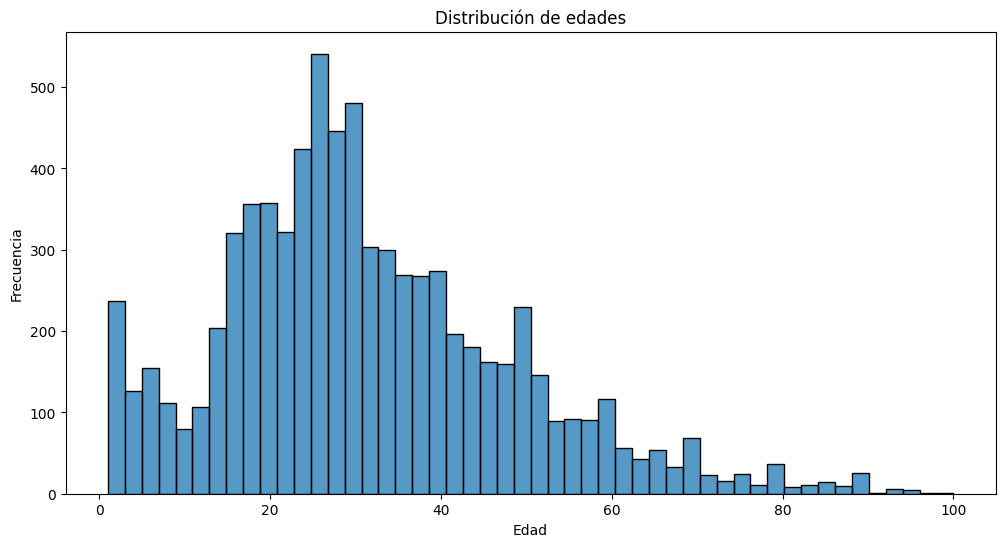

In [12]:
plt.figure(figsize=(12,6))

sns.histplot(
    labels['real_age'],
    bins=50
)

plt.title('Distribución de edades')
plt.xlabel('Edad')
plt.ylabel('Frecuencia')

plt.show()

La distribución de edades muestra una mayor concentración de observaciones entre los 20 y los 40 años, con un pico cercano a los 30 años. Esto indica que el conjunto de datos está compuesto principalmente por adultos jóvenes.

Aunque existen registros de edades comprendidas entre 1 y 100 años, la frecuencia de las observaciones disminuye progresivamente en los extremos de la distribución, especialmente para las personas mayores de 60 años. Esto evidencia un cierto desbalance en el conjunto de datos.

La presencia de ejemplos pertenecientes a un amplio rango de edades constituye una ventaja para el entrenamiento del modelo, ya que le permite aprender patrones faciales asociados a distintas etapas de la vida. Sin embargo, la menor representación de niños y adultos mayores podría generar una reducción en la precisión de las predicciones para estos grupos etarios.

En consecuencia, es esperable que el modelo obtenga un mejor desempeño en los rangos de edad más representados, especialmente entre los 20 y los 40 años, donde se concentra la mayor cantidad de fotografías disponibles para el aprendizaje.

In [13]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

datagen = ImageDataGenerator(rescale = 1./255)

generator = datagen.flow_from_dataframe(
    dataframe=labels,
    directory='/content/faces',
    x_col='file_name',
    y_col='real_age',
    target_size=(224,224),
    batch_size=16,
    class_mode='raw',
    seed=12345
)

Found 7591 validated image filenames.


In [14]:
features, target = next(generator)

In [15]:
features.shape

(16, 224, 224, 3)

Se creó exitosamente un generador de datos mediante ImageDataGenerator. El primer lote cargado contiene 16 imágenes redimensionadas a 224×224 píxeles y representadas mediante tres canales de color (RGB), lo que confirma que los datos están preparados para ser utilizados posteriormente por una red neuronal convolucional.

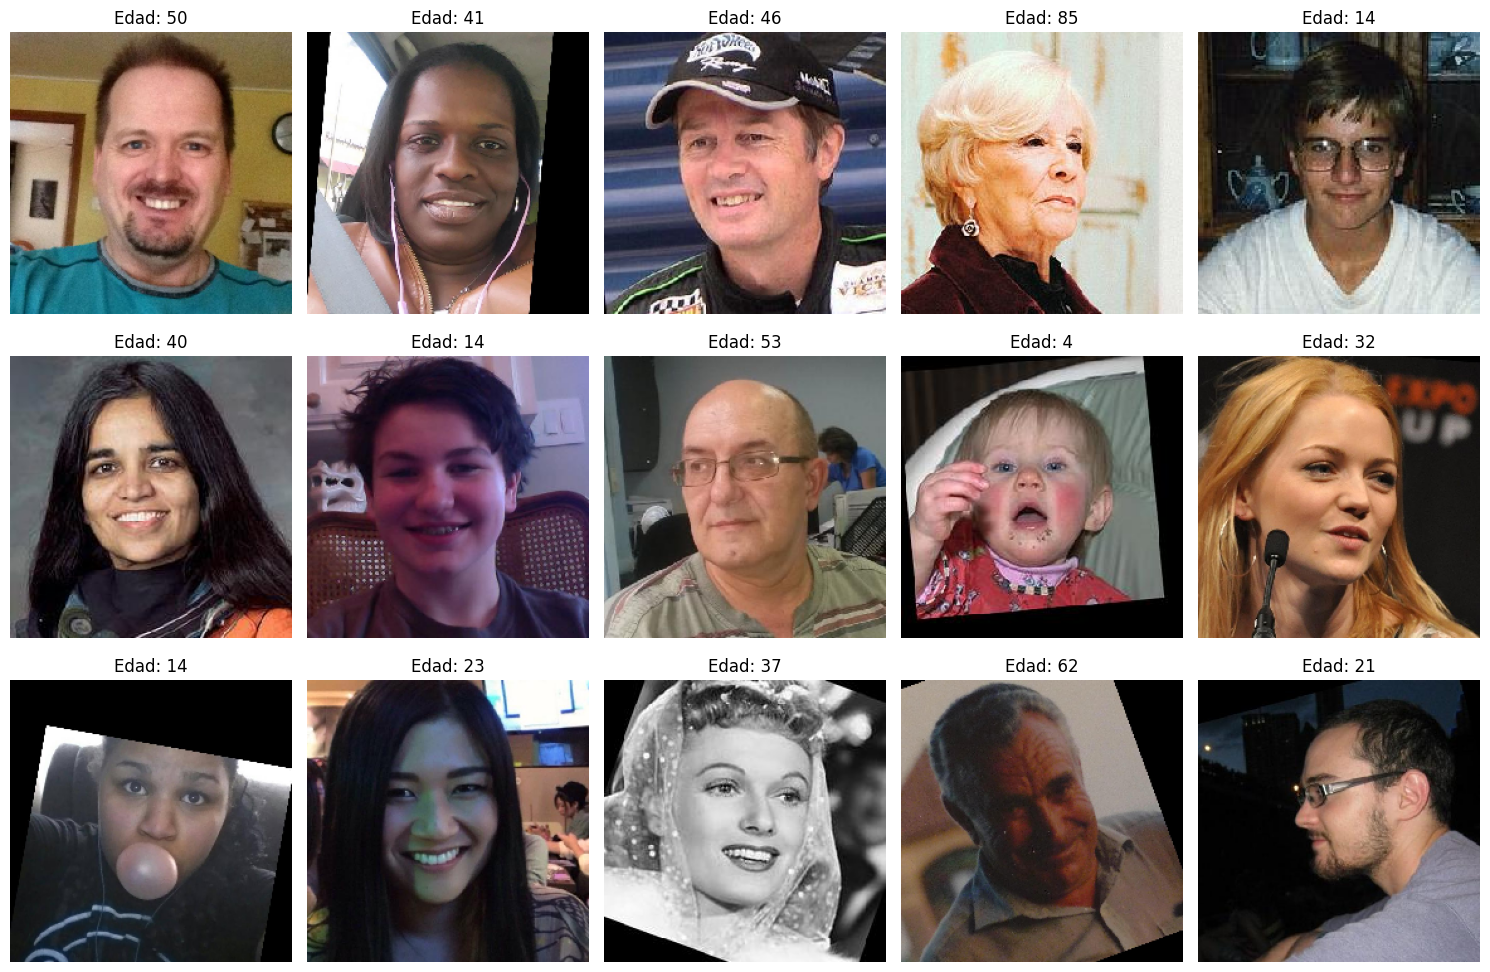

In [16]:
fig, axes = plt.subplots(
    3,
    5,
    figsize=(15, 10)
)

for i, ax in enumerate(axes.ravel()):

    ax.imshow(features[i])

    ax.set_title(
        f'Edad: {int(target[i])}'
    )

    ax.axis('off')

plt.tight_layout()

plt.show()

La inspección visual de las imágenes muestra una alta diversidad en el conjunto de datos. Se observan fotografías correspondientes a distintas etapas de la vida, desde niños pequeños hasta adultos mayores, lo que resulta favorable para el entrenamiento de un modelo de estimación de edad.

Las imágenes presentan variaciones en iluminación, orientación del rostro, calidad fotográfica, ángulo de captura y presencia de accesorios como gafas o gorras. Asimismo, se identifican tanto fotografías en color como algunas en escala de grises.

Esta diversidad incrementa la complejidad del problema, ya que el modelo deberá aprender a identificar características relacionadas con la edad en diferentes condiciones de captura. Sin embargo, también puede favorecer una mejor capacidad de generalización frente a imágenes nuevas.

En conjunto, el dataset parece adecuado para entrenar un modelo de visión artificial orientado a la predicción de edad, aunque el desbalance observado previamente en la distribución de edades podría generar un mejor desempeño en los grupos etarios más representados, especialmente entre los 20 y los 40 años.

## Modelado

In [26]:
import pandas as pd

import tensorflow as tf

from tensorflow import keras
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.resnet import ResNet50
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout, Flatten
from tensorflow.keras.optimizers import Adam

In [27]:
def load_train(path):

    labels = pd.read_csv(path + "labels.csv")

    datagen = ImageDataGenerator(rescale = 1./255, validation_split = 0.2)

    train_gen_flow = datagen.flow_from_dataframe(dataframe = labels, directory = (path + "faces"), y_col = "real_age", x_col = "file_name", target_size = (224, 224), batch_size = 15, subset = "training", seed = 12345, class_mode = "raw")

    return train_gen_flow

### Carga de los datos de entrenamiento

Se creó la función `load_train()` para cargar y preparar los datos de entrenamiento.

La función realiza las siguientes tareas:

- Carga el archivo `labels.csv`, que contiene los nombres de las imágenes y sus respectivas edades.
- Normaliza los valores de los píxeles mediante `rescale=1./255`.
- Reserva el 20% de los datos para validación mediante `validation_split=0.2`.
- Genera un flujo de imágenes utilizando `flow_from_dataframe()`.
- Redimensiona todas las imágenes a 224 × 224 píxeles para que sean compatibles con la red neuronal.
- Devuelve un generador listo para ser utilizado durante el entrenamiento del modelo.

El uso de un generador permite cargar las imágenes por lotes, reduciendo significativamente el consumo de memoria durante el entrenamiento.

In [19]:
def load_test(path):

    labels = pd.read_csv(path + "labels.csv")

    datagen = ImageDataGenerator(rescale = 1./255, validation_split = 0.2)

    test_gen_flow = datagen.flow_from_dataframe(dataframe = labels, directory = (path + "faces"), target_size = (224, 224), batch_size = 15, seed = 12345, class_mode = "raw", subset = "validation", y_col = "real_age", x_col = "file_name")

    return test_gen_flow

In [25]:
from tensorflow import keras
from tensorflow.keras.applications.resnet import ResNet50

def create_model(input_shape):

    model_base = ResNet50(input_shape = input_shape, weights = "imagenet", include_top = False)

    model = keras.models.Sequential([model_base])

    model.add(keras.layers.GlobalAveragePooling2D())
    model.add(keras.layers.Dense(units = 1, activation = "relu"))

    optimizer = Adam(learning_rate = 0.001)

    model.compile(loss = "mse", optimizer = optimizer, metrics = ["mae"])

    return model

### Creación y compilación del modelo

Se construyó un modelo de aprendizaje profundo basado en la arquitectura preentrenada ResNet50 utilizando los pesos de ImageNet. Para adaptar la red a la tarea de estimación de edad, se eliminó la capa de salida original mediante `include_top=False`.

Posteriormente, se añadió una capa `GlobalAveragePooling2D()` para reducir la dimensionalidad de las características extraídas por la red y una capa `Dense` con una única neurona, encargada de generar la predicción de edad.

El modelo fue compilado utilizando el optimizador Adam con una tasa de aprendizaje de 0.001. Se empleó el Error Cuadrático Medio (MSE) como función de pérdida y el Error Absoluto Medio (MAE) como métrica de evaluación principal debido a que se trata de un problema de regresión en el que se busca predecir una edad numérica.

In [21]:
def train_model(model, train_data, test_data, batch_size=None, epochs=20,
                steps_per_epoch=None, validation_steps=None):

    model.fit(
        train_data,
        validation_data=test_data,
        batch_size=batch_size,
        epochs=epochs,
        steps_per_epoch=steps_per_epoch,
        validation_steps=validation_steps,
        verbose=1
    )

    return model

In [22]:
# prepara un script para ejecutarlo en la plataforma GPU

init_str = """
import pandas as pd

import tensorflow as tf

from tensorflow import keras
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.resnet import ResNet50
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout, Flatten
from tensorflow.keras.optimizers import Adam
"""

import inspect

with open('run_model_on_gpu.py', 'w') as f:

    f.write(init_str)
    f.write('\n\n')

    for fn_name in [load_train, load_test, create_model, train_model]:

        src = inspect.getsource(fn_name)
        f.write(src)
        f.write('\n\n')

In [23]:
!cat run_model_on_gpu.py


import pandas as pd

import tensorflow as tf

from tensorflow import keras
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.resnet import ResNet50
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout, Flatten
from tensorflow.keras.optimizers import Adam


def load_train(path):
    
    labels = pd.read_csv(path + "labels.csv")

    datagen = ImageDataGenerator(rescale = 1./255, validation_split = 0.2)

    train_gen_flow = datagen.flow_from_dataframe(dataframe = labels, directory = (path + "faces"), y_col = "real_age", x_col = "file_name", target_size = (224, 224), batch_size = 15, subset = "training", seed = 12345, class_mode = "raw")
    
    return train_gen_flow


def load_test(path):
    
    labels = pd.read_csv(path + "labels.csv")

    datagen = ImageDataGenerator(rescale = 1./255, validation_split = 0.2)

    test_gen_flow = datagen.flow_from_dataframe(da

In [28]:
model = create_model((224, 224, 3))
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │         2,049 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,589,761 (89.99 MB)

 Trainable params: 23,536,641 (89.79 MB)

 Non-trainable params: 53,120 (207.50 KB)

In [29]:
train_data = load_train('/content/')

Found 6073 validated image filenames.


In [30]:
test_data = load_test('/content/')

Found 1518 validated image filenames.


In [31]:
model = create_model((224,224,3))

In [33]:
model.fit(
    train_data,
    validation_data=test_data,
    epochs=1,
    verbose = 2
)

405/405 - 163s - 403ms/step - loss: 254.1660 - mae: 12.2069 - val_loss: 387.9894 - val_mae: 14.6921


### Resultado preliminar del entrenamiento

Se realizó una primera prueba de entrenamiento utilizando una única época con el objetivo de verificar el correcto funcionamiento del flujo completo de procesamiento de datos, la arquitectura basada en ResNet50 y el proceso de optimización.

Resultados obtenidos:

- Loss (entrenamiento): 254.1660
- MAE (entrenamiento): 12.2069
- Loss (validación): 387.9894
- MAE (validación): 14.6921

Estos resultados indican que el modelo logró aprender patrones relacionados con la edad desde la primera época de entrenamiento. El Error Absoluto Medio (MAE) de validación fue de aproximadamente 14.7 años, lo que significa que las predicciones difieren de la edad real en cerca de 15 años en promedio.

Dado que el modelo solo fue entrenado durante una época, estos resultados deben considerarse preliminares. Es esperable que el error disminuya a medida que aumente el número de épocas y la red tenga más oportunidades para ajustar sus parámetros a las características faciales presentes en el conjunto de datos.

In [34]:
import tensorflow as tf

tf.config.list_physical_devices('GPU')

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

Antes de iniciar el entrenamiento completo, se verificó la disponibilidad de una GPU mediante TensorFlow. El entorno detectó correctamente un dispositivo GPU, lo que permitirá acelerar significativamente el proceso de entrenamiento de la red neuronal ResNet50.

In [35]:
model.fit(
    train_data,
    validation_data=test_data,
    epochs=20,
    verbose=2
)

Epoch 1/20
405/405 - 73s - 180ms/step - loss: 190.2821 - mae: 10.6961 - val_loss: 428.7262 - val_mae: 15.5208
Epoch 2/20
405/405 - 73s - 180ms/step - loss: 155.4244 - mae: 9.5403 - val_loss: 173.7286 - val_mae: 9.8796
Epoch 3/20
405/405 - 73s - 181ms/step - loss: 140.6261 - mae: 9.0859 - val_loss: 178.8485 - val_mae: 10.4310
Epoch 4/20
405/405 - 78s - 192ms/step - loss: 115.8614 - mae: 8.2669 - val_loss: 191.6097 - val_mae: 10.4873
Epoch 5/20
405/405 - 74s - 184ms/step - loss: 96.1043 - mae: 7.5380 - val_loss: 152.9270 - val_mae: 9.8744
Epoch 6/20
405/405 - 73s - 181ms/step - loss: 79.6553 - mae: 6.8922 - val_loss: 161.7274 - val_mae: 10.1720
Epoch 7/20
405/405 - 74s - 182ms/step - loss: 61.2241 - mae: 6.0334 - val_loss: 137.4333 - val_mae: 8.8068
Epoch 8/20
405/405 - 73s - 181ms/step - loss: 48.8411 - mae: 5.4230 - val_loss: 133.3699 - val_mae: 8.7255
Epoch 9/20
405/405 - 74s - 182ms/step - loss: 38.0195 - mae: 4.8165 - val_loss: 137.9472 - val_mae: 9.4106
Epoch 10/20
405/405 - 73s - 

## Conclusiones

El objetivo del proyecto fue desarrollar un modelo de visión artificial capaz de estimar la edad de una persona a partir de una fotografía facial para ayudar a la cadena de supermercados Good Seed a cumplir las restricciones legales relacionadas con la venta de alcohol a menores de edad.

Durante el análisis exploratorio se observó que el conjunto de datos contiene 7.591 imágenes con edades comprendidas entre 1 y 100 años. La distribución de edades presenta una mayor concentración en adultos jóvenes y de mediana edad, mientras que los extremos del rango etario poseen una representación menor.

Para la tarea de predicción de edad se utilizó una red neuronal convolucional basada en ResNet50 preentrenada con pesos de ImageNet. Tras 20 épocas de entrenamiento, el mejor rendimiento se obtuvo en la época 18, alcanzando un MAE de validación de aproximadamente 8.13 años.

Los resultados indican que el modelo es capaz de estimar la edad con un nivel de precisión razonable. En promedio, las predicciones difieren de la edad real en alrededor de ocho años. Aunque este error no es suficientemente pequeño para sustituir completamente la verificación mediante documentos de identidad, sí podría utilizarse como un sistema de apoyo para identificar clientes potencialmente menores de edad y generar alertas para que el personal solicite una verificación adicional.

Adicionalmente, una tecnología de este tipo podría utilizarse para realizar análisis demográficos de clientes, segmentación por grupos de edad, estudios de mercado y optimización de campañas publicitarias dentro de las tiendas.

En conclusión, la visión artificial puede servir como una herramienta de apoyo para la verificación de edad en Good Seed, aunque no debería utilizarse como único mecanismo de validación debido al margen de error observado.